# YZM 411 Bilgisayarlı Görü — Ödev 1: Renk, Aydınlatma ve Örnekleme

**Öğrenci:** Nisa Duru — **No:** 230212903

## Çalıştırma sırası
1. Özgün fotoğraflar `fotograflar/` klasöründedir (`normal`, `golge`, `lamba`).
2. **Parametreler** hücresinde sahne koordinatları, örnek bölge ve eşikler tanımlanmıştır.
3. **Tahminler** hücresi deneyler çalıştırılmadan önce doldurulmuştur.
4. *Kernel → Restart & Run All* ile baştan sona çalıştırıldığında tüm görseller ve tablolar `ciktilar/` klasörüne yazılır.
5. Her deneyin altındaki **Gözlem** hücrelerinde ölçüm sonuçları yorumlanmıştır.

In [1]:
import os, json, platform, datetime, zipfile
import numpy as np
import cv2
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image, ExifTags

try:
    display
except NameError:          # Jupyter dışında çalıştırılırsa
    display = print

pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 110

print("Çalıştırma zamanı:", datetime.datetime.now().isoformat(timespec="seconds"))
SURUMLER = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "opencv": cv2.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "pillow": Image.__version__,
    "platform": platform.platform(),
}
for k, v in SURUMLER.items():
    print(f"{k:11s} {v}")

Çalıştırma zamanı: 2026-11-10T17:51:57
python      3.12.9
numpy       2.4.4
opencv      4.12.0
pandas      3.0.2
matplotlib  3.10.8
pillow      11.3.0
platform    macOS-27.2-arm64-arm-64bit


## Parametreler
Ayarlanabilir bütün değerler bu hücrededir. Koordinatlar **(x, y)** biçimindedir: x = sütun (soldan sağa), y = satır (yukarıdan aşağıya). Hizalama açıkken koordinatlar **hizalanmış ve kırpılmış** görüntüye aittir.
Koordinatlar Adım 4.0'daki ızgaralı görselden okunmuştur.

In [2]:
# ===== PARAMETRELER =====
ACIKLAMA = "Turuncu mandalina + çay bardağı + 'PentaPoint' yazılı prospektüs kartı + beyaz A4 kağıt, bej masa"
FOTOLAR = {"normal": "IMG_7106.JPG", "golge": "IMG_7104.JPG", "lamba": "IMG_7107.JPG"}
KAMERA_NOTU = "iPhone 16 Pro Max, 24 MP JPEG (4284x5712); otomatik pozlama ve otomatik beyaz dengesi açık (EXIF: ExposureMode=0, WhiteBalance=0, ISO=160, ExposureTime=0.01 s); flaş kapalı; kamera çekimler arasında hafif hareket ettiği için SIFT+RANSAC ile hizalandı; gölge kaynağı: tavan ışığının cisimle perdelenmesi; lamba: üstten tutulan soğuk beyaz LED ışık."

PIKSELLER = [(2180, 2520), (2320, 2580), (1750, 3400)]   # Adım 4 — üç piksel (x, y)
ORNEK_BOLGE = (2140, 2460, 220, 200)                      # Adım 5 — nesne üzerinde örnek bölge (x, y, gen., yük.)
RGB_ESIK = {'R': (150, 215), 'G': (100, 155), 'B': (40, 90)}
HSV_ESIK = {'H': (12, 22), 'S': (120, 205), 'V': (140, 220)}
YAZI_BOLGESI = (2380, 2940, 640, 760)                    # Adım 7 — yazılı/desenli bölge (x, y, gen., yük.)

GIRIS_KLASORU = "fotograflar"
CIKTI_KLASORU = "ciktilar"
SAHNE = "NisaDuru"

# Kamera sabit kalmadıysa gölge ve lamba fotoğrafları normal fotoğrafa hizalanır, üçü ortak alana kırpılır
HIZALA = True

KOMSULUK = 5                     # Adım 4 — piksel çevresindeki k×k kare ortalaması
PARLAKLIK_B = 40                 # Adım 6
GAMALAR = [0.5, 2.0]
KUCULTME = 4                     # Adım 7

# Teslim — ZIP adı: YZM411_Odev1_<OGRENCI_NO>.zip
OGRENCI_NO = "230212903"

## Tahminler
Her deneyin tahmini, deney çalıştırılmadan **önce** en az iki cümleyle yazılmıştır: hangi ayrıntı veya hata değişecek, neden?
Tahmini boş kalan bir deney olursa kod uyarı verir.

In [3]:
# ===== TAHMİNLER =====
TAHMINLER = {
    "adim4_piksel": "Seçtiğim turuncu mandalina ve beyaz A4 kağıdı piksellerinin gölge düşürüldüğünde kararacağını (R, G, B sayılarının küçüleceğini), üstten lamba tutulduğunda ise parlayarak artacağını düşünüyorum. Aynı bölgedeki 5×5 komşu pikseller de birbirine yakın değerler alacaktır.",
    "adim5_esik": "Sabit RGB eşikleriyle yaptığım maskenin normal fotoğrafta mandalinayı iyi yakalayacağını, ancak gölgede mandalina kararınca piksellerin çoğunu kaçıracağını düşünüyorum. HSV maskesinin ise ışık değişse bile mandalinanın turuncu tonunu tanımaya devam edeceğini ama sıcak/sarımsı masa ve duvar yüzeylerinden de parçalar seçebileceğini tahmin ediyorum.",
    "adim6_parlaklik": "Görüntüye +40 parlaklık eklediğimde tüm fotoğrafın açılacağını ve ortalamanın yaklaşık 40 puan yükseleceğini tahmin ediyorum. Beyaz kağıt gibi çok açık renkli bölgelerin 255'i geçerek kırpılacağını ve ortalamayı 150.86'nın biraz altına düşüreceğini öngörüyorum.",
    "adim6_gama": "γ = 0.5 uygulandığında gölgede kalan masa ve çay bardağı kısımlarının açılıp genel ortalamanın yaklaşık 168 civarına yükseleceğini tahmin ediyorum. γ = 2.0 uygulandığında ise koyu ve orta tonların iyice siyaha yaklaşarak ortalamayı 48 civarına düşüreceğini öngörüyorum.",
    "adim7_kucultme": "A4 kağıdı üzerindeki 'PentaPoint' yazılı prospektüs kartını 1/4 oranında küçültüp geri büyüttüğümde üstteki küçük açıklama yazılarının okunmaz hale geleceğini, büyük başlığın ise okunacağını düşünüyorum. INTER_NEAREST yönteminde harflerin tırtıklı ve kopuk görüneceğini, INTER_AREA yönteminde ise bulanıklaşsa bile harf şekillerinin daha bütün kalacağını tahmin ediyorum."
}

def tahmini_goster(anahtar):
    metin = TAHMINLER.get(anahtar, "").strip()
    if metin:
        print(f"TAHMİN ({anahtar}): {metin}")
    else:
        print(f"UYARI: '{anahtar}' için tahmin yazılmamış. Tahmini olmayan deney puanlanmaz.")

## Fotoğrafları okuma ve kamera bilgisi

In [4]:
# --- parametre denetimi
assert KOMSULUK >= 1 and KOMSULUK % 2 == 1, "KOMSULUK tek sayı olmalı (1, 3, 5, ...)."
for kanal, (a, b) in RGB_ESIK.items():
    assert 0 <= a <= b <= 255, f"RGB_ESIK[{kanal}] = {(a, b)}: 0 ≤ alt ≤ üst ≤ 255 olmalı."
for kanal, (a, b) in HSV_ESIK.items():
    ust = 179 if kanal == "H" else 255
    assert 0 <= a <= ust and 0 <= b <= ust, f"HSV_ESIK[{kanal}] = {(a, b)}: değerler 0–{ust} aralığında olmalı."
    assert kanal == "H" or a <= b, f"HSV_ESIK[{kanal}] = {(a, b)}: alt ≤ üst olmalı (yalnız H 0'ı sarabilir)."
assert KUCULTME >= 2 and min(YAZI_BOLGESI[2:]) >= 8 * KUCULTME, \
    f"YAZI_BOLGESI en az {8 * KUCULTME}×{8 * KUCULTME} piksel olmalı."

SABLON_VARSAYILANLARI = {
    "PIKSELLER": [(1520, 980), (1600, 1010), (2400, 1500)],
    "ORNEK_BOLGE": (1450, 900, 120, 120),
    "YAZI_BOLGESI": (2000, 1800, 800, 400),
    "RGB_ESIK": {"R": (151, 255), "G": (101, 255), "B": (0, 79)},
    "HSV_ESIK": {"H": (18, 30), "S": (121, 255), "V": (81, 255)},
}
for ad, v in SABLON_VARSAYILANLARI.items():
    if globals()[ad] == v:
        print(f"UYARI: {ad} hâlâ şablondaki örnek değer (ödev PDF'indeki temsilî sayılar). Kendi fotoğrafına göre seç.")
if "..." in KAMERA_NOTU:
    print("UYARI: KAMERA_NOTU doldurulmamış.")

os.makedirs(CIKTI_KLASORU, exist_ok=True)

def cikti(ad):
    return os.path.join(CIKTI_KLASORU, ad)

def oku(anahtar):
    yol = os.path.join(GIRIS_KLASORU, FOTOLAR[anahtar])
    img = cv2.imread(yol, cv2.IMREAD_COLOR)     # OpenCV BGR sırasıyla okur ve EXIF yönünü uygular
    if img is None:
        raise FileNotFoundError(f"{yol} okunamadı. Dosya adı ve uzantısı doğru mu? HEIC ise JPG'ye çevir.")
    return img

print("Sahne:", SAHNE, "—", ACIKLAMA)
BGR_HAM = {k: oku(k) for k in FOTOLAR}
for k, im in BGR_HAM.items():
    print(f"{k:7s} {os.path.join(GIRIS_KLASORU, FOTOLAR[k])}  özgün shape={im.shape}")
if not HIZALA:
    assert len({im.shape for im in BGR_HAM.values()}) == 1, \
        "Üç fotoğrafın boyutu aynı olmalı (aynı kamera, aynı çözünürlük, aynı yön)."

def kucult_goster(img, en=1200):
    # yalnızca ekranda göstermek için; ölçümler hep özgün çözünürlükte yapılır
    if img.shape[1] <= en:
        return img
    o = en / img.shape[1]
    return cv2.resize(img, (en, round(img.shape[0] * o)), interpolation=cv2.INTER_AREA)

Sahne: NisaDuru — Turuncu mandalina + çay bardağı + 'PentaPoint' yazılı prospektüs kartı + beyaz A4 kağıt, bej masa


normal  fotograflar/IMG_7106.JPG  özgün shape=(5712, 4284, 3)
golge   fotograflar/IMG_7104.JPG  özgün shape=(5712, 4284, 3)
lamba   fotograflar/IMG_7107.JPG  özgün shape=(5712, 4284, 3)


## Hizalama (kamera sabit kalmadı)
Çekimler arasında telefon hareket ettiği için aynı fiziksel nokta üç fotoğrafta farklı piksellere düşüyor. Bu yüzden:
1. Gölge ve lamba fotoğraflarında normal fotoğrafla ortak noktalar bulunur (SIFT, oran testi), RANSAC ile bir homografi kestirilir.
2. Bu iki fotoğraf homografiyle normal fotoğrafın üstüne oturtulur (`cv2.warpPerspective`, `INTER_LINEAR`).
3. Üç fotoğraf da hepsinde dolu olan ortak dikdörtgene kırpılır. Bundan sonraki bütün ölçümler bu kırpılmış görüntülerde yapılır.

**Sınırlar:**
- Normal fotoğraf yeniden örneklenmez, yalnız kırpılır.
- Gölge ve lamba fotoğrafları ara değerlemeyle yeniden örneklenir; keskin kenarlar biraz yumuşar, piksel değerleri az da olsa değişir.
- Homografi düzlemsel sahne varsayar: masa düzleminde hata birkaç piksel, masadan yüksekte duran nesnelerde biraz daha fazla olabilir (paralaks). Bu yüzden pikseller ve örnek bölge nesnelerin kenarından uzakta seçildi.

In [5]:
def ozellik_hazirla(bgr, en_uzun=1600):
    s = en_uzun / max(bgr.shape[:2])
    g = cv2.resize(cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY), None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return cv2.equalizeHist(g), s           # histogram eşitleme: ışık farkına rağmen eşleşme bulunsun

def hizala(ref_bgr, bgr, oran=0.7):
    g_ref, s_ref = ozellik_hazirla(ref_bgr)
    g_img, s_img = ozellik_hazirla(bgr)
    sift = cv2.SIFT_create(8000)
    k_ref, d_ref = sift.detectAndCompute(g_ref, None)
    k_img, d_img = sift.detectAndCompute(g_img, None)
    eslesme = [p[0] for p in cv2.BFMatcher().knnMatch(d_img, d_ref, k=2)
               if len(p) == 2 and p[0].distance < oran * p[1].distance]
    if len(eslesme) < 30:
        raise RuntimeError(f"Yalnızca {len(eslesme)} ortak nokta bulundu; hizalama güvenilir değil.")
    p_img = np.float32([k_img[m.queryIdx].pt for m in eslesme])
    p_ref = np.float32([k_ref[m.trainIdx].pt for m in eslesme])
    Hk, inl = cv2.findHomography(p_img, p_ref, cv2.RANSAC, 2.0)
    inl = inl.ravel().astype(bool)
    # küçük kopyada bulunan homografiyi özgün çözünürlüğe taşı
    H_tam = np.diag([1 / s_ref, 1 / s_ref, 1.0]) @ Hk @ np.diag([s_img, s_img, 1.0])
    kayma = np.linalg.norm(p_img[inl] / s_img - p_ref[inl] / s_ref, axis=1)
    kalan = np.linalg.norm(cv2.perspectiveTransform(p_img[inl][None], Hk)[0] - p_ref[inl], axis=1) / s_ref
    yh, yw = ref_bgr.shape[:2]
    hizali = cv2.warpPerspective(bgr, H_tam, (yw, yh), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT)
    gecerli = cv2.warpPerspective(np.full(bgr.shape[:2], 255, np.uint8), H_tam, (yw, yh), flags=cv2.INTER_NEAREST)
    gecerli = cv2.erode(gecerli, np.ones((7, 7), np.uint8)) > 0     # kenardaki karışık pikselleri at
    bilgi = {"eşleşme": len(eslesme), "RANSAC_inlier": int(inl.sum()),
             "hizalama_öncesi_kayma_medyan_px": float(np.median(kayma)), "hizalama_öncesi_kayma_max_px": float(kayma.max()),
             "hizalama_sonrası_hata_medyan_px": float(np.median(kalan)), "hizalama_sonrası_hata_%90_px": float(np.percentile(kalan, 90))}
    return hizali, gecerli, H_tam, bilgi

def ic_dikdortgen(maske, k=8):
    # maskenin tamamen dolu olduğu eksene paralel bir dikdörtgen: en boş kenarı içeri çekerek küçült
    m = maske[::k, ::k]
    y0, y1, x0, x1 = 0, m.shape[0], 0, m.shape[1]
    while not m[y0:y1, x0:x1].all():
        a = m[y0:y1, x0:x1]
        bos = {"ust": 1 - a[0].mean(), "alt": 1 - a[-1].mean(), "sol": 1 - a[:, 0].mean(), "sag": 1 - a[:, -1].mean()}
        yon = max(bos, key=bos.get)
        if yon == "ust": y0 += 1
        elif yon == "alt": y1 -= 1
        elif yon == "sol": x0 += 1
        else: x1 -= 1
    x, y, w, h = (x0 + 1) * k, (y0 + 1) * k, (x1 - x0 - 2) * k, (y1 - y0 - 2) * k
    while not maske[y:y + h, x:x + w].all():
        x, y, w, h = x + k, y + k, w - 2 * k, h - 2 * k
    assert w > 0 and h > 0, "Ortak alan bulunamadı."
    return int(x), int(y), int(w), int(h)

if HIZALA:
    hizali = {"normal": BGR_HAM["normal"]}
    ortak = np.ones(BGR_HAM["normal"].shape[:2], bool)
    satirlar, HOMOGRAFI = [], {}
    for k in ("golge", "lamba"):
        hizali[k], gecerli, HOMOGRAFI[k], bilgi = hizala(BGR_HAM["normal"], BGR_HAM[k])
        ortak &= gecerli
        satirlar.append({"foto": k, **bilgi})
    KIRP = ic_dikdortgen(ortak)
    x, y, w, h = KIRP
    BGR = {k: np.ascontiguousarray(v[y:y + h, x:x + w]) for k, v in hizali.items()}
    HIZALAMA_TABLO = pd.DataFrame(satirlar)
    HIZALAMA_TABLO.to_csv(cikti("hizalama.csv"), index=False, encoding="utf-8-sig")
    display(HIZALAMA_TABLO)
    oh, ow = BGR_HAM["normal"].shape[:2]
    print(f"Ortak alan (normal fotoğrafın koordinatında): x={x}, y={y}, genişlik={w}, yükseklik={h} "
          f"— özgün alanın %{100 * w * h / (ow * oh):.1f}'i")
    HIZALAMA_BILGI = {
        "yontem": "SIFT (1600 px kopya, histogram eşitleme) + oran testi 0.7 + RANSAC homografi (2 px); "
                  "warpPerspective INTER_LINEAR; ortak dikdörtgene kırpma",
        "referans": FOTOLAR["normal"], "kirpma_xywh": list(KIRP),
        "homografi": {k: np.round(v, 8).tolist() for k, v in HOMOGRAFI.items()},
        "olcumler": satirlar}
else:
    BGR = dict(BGR_HAM)
    HIZALAMA_BILGI = {"yontem": "hizalama yapılmadı"}

RGB = {k: cv2.cvtColor(im, cv2.COLOR_BGR2RGB) for k, im in BGR.items()}
H, W, C = BGR["normal"].shape
print("Ölçümlerde kullanılan görüntü boyutu (H, W, C):", (H, W, C))

,foto,eşleşme,RANSAC_inlier,hizalama_öncesi_kayma_medyan_px,hizalama_öncesi_kayma_max_px,hizalama_sonrası_hata_medyan_px,hizalama_sonrası_hata_%90_px
0,golge,270,246,57.696,66.193,0.941,2.599
1,lamba,250,224,41.214,68.633,0.913,2.304


Ortak alan (normal fotoğrafın koordinatında): x=48, y=96, genişlik=4120, yükseklik=5584 — özgün alanın %94.0'i
Ölçümlerde kullanılan görüntü boyutu (H, W, C): (5584, 4120, 3)


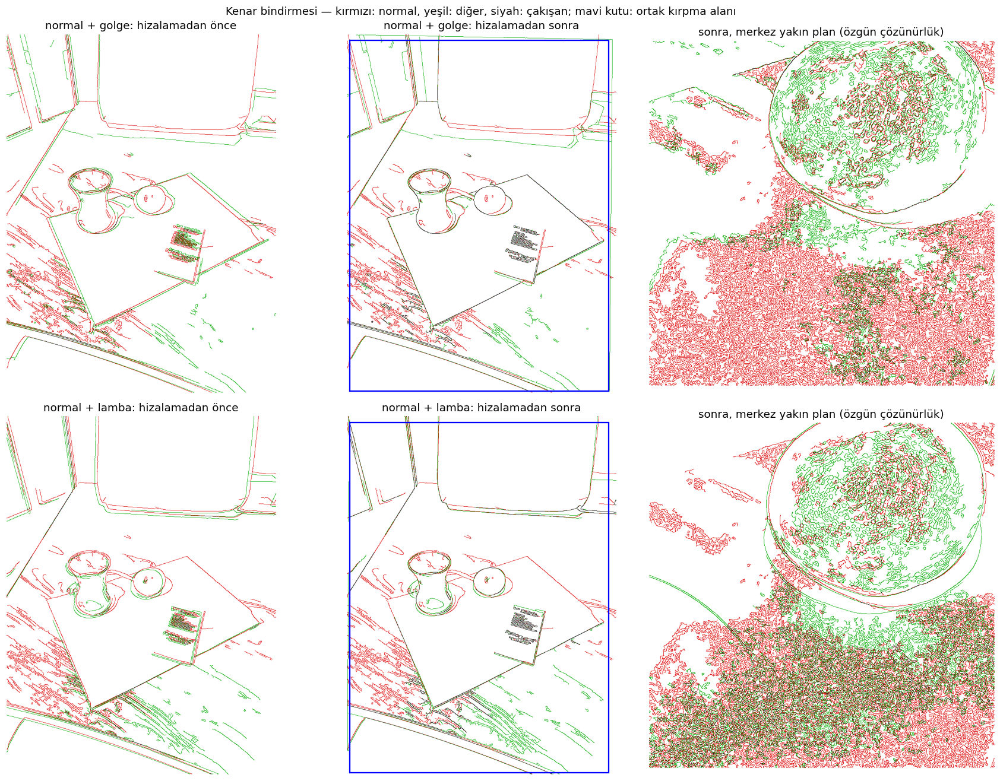

In [6]:
# Hizalama kontrolü: kırmızı = normal fotoğrafın kenarları, yeşil = diğer fotoğrafın kenarları, siyah = çakışan
def kenar(bgr, boyut):
    g = cv2.cvtColor(cv2.resize(bgr, boyut, interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2GRAY)
    return cv2.Canny(cv2.GaussianBlur(cv2.equalizeHist(g), (5, 5), 0), 40, 120) > 0

def bindirme(a, b, boyut):
    ka, kb = kenar(a, boyut), kenar(b, boyut)
    g = np.full((*ka.shape, 3), 255, np.uint8)
    g[ka] = (220, 0, 0); g[kb] = (0, 170, 0); g[ka & kb] = (0, 0, 0)
    return g

if HIZALA:
    oh, ow = BGR_HAM["normal"].shape[:2]
    boyut = (700, round(700 * oh / ow))
    cy, cx, r = oh // 2, ow // 2, 400                        # merkezde 800×800 piksellik yakın plan
    fig, ax = plt.subplots(2, 3, figsize=(16, 2 * 16 / 3 * boyut[1] / boyut[0] * 0.75 + 1.5))
    for i, k in enumerate(("golge", "lamba")):
        ax[i, 0].imshow(bindirme(BGR_HAM["normal"], BGR_HAM[k], boyut)); ax[i, 0].set_title(f"normal + {k}: hizalamadan önce")
        ax[i, 1].imshow(bindirme(BGR_HAM["normal"], hizali[k], boyut)); ax[i, 1].set_title(f"normal + {k}: hizalamadan sonra")
        x, y, w, h = KIRP; o = boyut[0] / ow
        ax[i, 1].add_patch(plt.Rectangle((x * o, y * o), w * o, h * o, fill=False, ec="blue", lw=1.5))
        ax[i, 2].imshow(bindirme(BGR_HAM["normal"][cy - r:cy + r, cx - r:cx + r], hizali[k][cy - r:cy + r, cx - r:cx + r], (2 * r, 2 * r)))
        ax[i, 2].set_title("sonra, merkez yakın plan (özgün çözünürlük)")
    for a in ax.ravel(): a.axis("off")
    fig.suptitle("Kenar bindirmesi — kırmızı: normal, yeşil: diğer, siyah: çakışan; mavi kutu: ortak kırpma alanı")
    fig.tight_layout(); fig.savefig(cikti("00_hizalama.png"), dpi=130); plt.show()

In [7]:
EXIF_ALANLARI = ["Make", "Model", "DateTimeOriginal", "ExposureTime", "FNumber", "ISOSpeedRatings",
                 "PhotographicSensitivity", "ExposureBiasValue", "ExposureMode", "ExposureProgram",
                 "WhiteBalance", "Flash"]

def exif_oku(yol):
    try:
        with Image.open(yol) as im:
            ex = im.getexif()
            tum = dict(ex)
            try:
                tum.update(ex.get_ifd(0x8769))  # Exif alt bölümü (pozlama, ISO, beyaz dengesi)
            except Exception:
                pass
        return {ExifTags.TAGS.get(k, k): str(v) for k, v in tum.items() if ExifTags.TAGS.get(k, k) in EXIF_ALANLARI}
    except Exception as e:
        return {"hata": str(e)}

EXIF = pd.DataFrame({k: exif_oku(os.path.join(GIRIS_KLASORU, f)) for k, f in FOTOLAR.items()}).T
display(EXIF if len(EXIF.columns) else "EXIF bilgisi bulunamadı (fotoğraf aktarılırken silinmiş olabilir).")
print("WhiteBalance: 0 = otomatik, 1 = elle | ExposureMode: 0 = otomatik, 1 = elle, 2 = otomatik basamaklama")
print("Kamera notu:", KAMERA_NOTU)

,Make,Model,DateTimeOriginal,ExposureBiasValue,Flash,ExposureTime,FNumber,ExposureProgram,ISOSpeedRatings,ExposureMode,WhiteBalance
normal,Apple,iPhone 16 Pro Max,2026:11:09 17:26:21,0.0,16,0.01,1.7799999713880652,2,160,0,0
golge,Apple,iPhone 16 Pro Max,2026:11:09 17:26:10,0.0,16,0.01,1.7799999713880652,2,160,0,0
lamba,Apple,iPhone 16 Pro Max,2026:11:09 17:26:39,0.0,16,0.01,1.7799999713880652,2,160,0,0


WhiteBalance: 0 = otomatik, 1 = elle | ExposureMode: 0 = otomatik, 1 = elle, 2 = otomatik basamaklama
Kamera notu: iPhone 16 Pro Max, 24 MP JPEG (4284x5712); otomatik pozlama ve otomatik beyaz dengesi açık (EXIF: ExposureMode=0, WhiteBalance=0, ISO=160, ExposureTime=0.01 s); flaş kapalı; kamera çekimler arasında hafif hareket ettiği için SIFT+RANSAC ile hizalandı; gölge kaynağı: tavan ışığının cisimle perdelenmesi; lamba: üstten tutulan soğuk beyaz LED ışık.


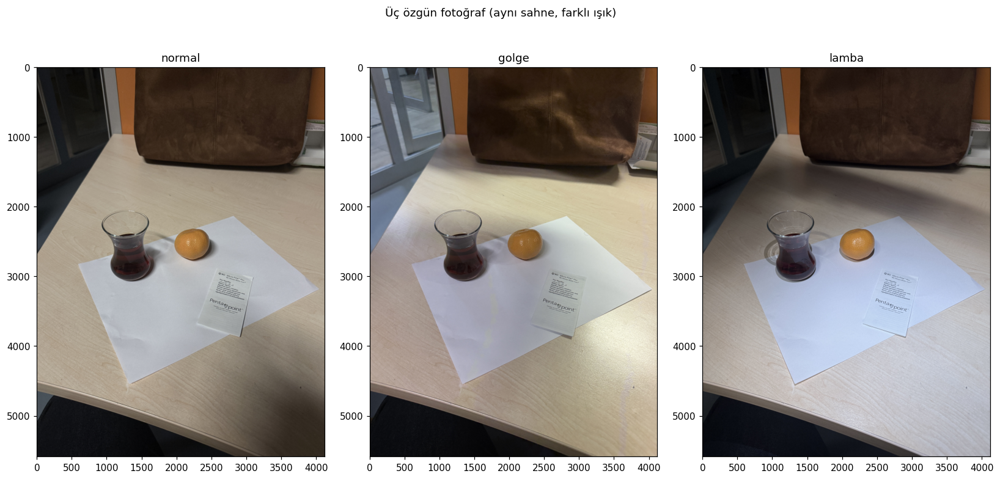

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5 * H / W + 0.8))
for a, k in zip(ax, FOTOLAR):
    a.imshow(kucult_goster(RGB[k]), extent=(0, W, H, 0))
    a.set_title(k)
fig.suptitle("Üç özgün fotoğraf (aynı sahne, farklı ışık)")
fig.tight_layout(); fig.savefig(cikti("01_fotograflar.png"), dpi=150); plt.show()

## Adım 4 — Görüntünün sayısal yapısı (Hedef 1)

### 4.0 Koordinat yardımcısı
Eksenler özgün piksel koordinatlarını gösterir. Kırmızı noktalar `PIKSELLER`, yeşil kutu `ORNEK_BOLGE`, mavi kutu `YAZI_BOLGESI`.
Noktaların ve kutuların doğru nesnelerin üzerinde olduğu bu görselle kontrol edildi.

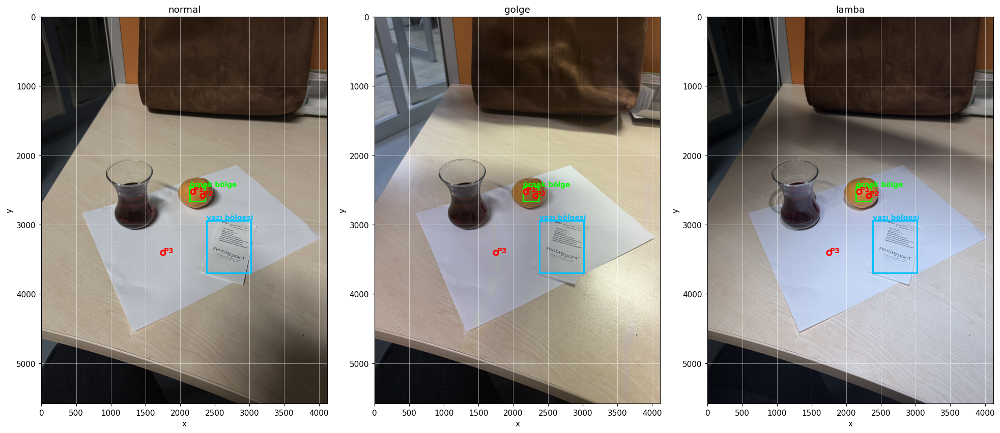

In [9]:
def kutu(a, b, renk, etiket):
    x, y, w, h = b
    a.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec=renk, lw=2))
    a.text(x, y - 10, etiket, color=renk, fontsize=9, weight="bold")

fig, ax = plt.subplots(1, 3, figsize=(18, 6 * H / W + 0.8))
for a, k in zip(ax, FOTOLAR):
    a.imshow(kucult_goster(RGB[k]), extent=(0, W, H, 0))
    a.grid(True, color="white", alpha=0.5, lw=0.6)
    for i, (x, y) in enumerate(PIKSELLER, 1):
        a.plot(x, y, "o", ms=6, mfc="none", mec="red", mew=2)
        a.text(x + 15, y, f"P{i}", color="red", fontsize=9, weight="bold")
    kutu(a, ORNEK_BOLGE, "lime", "örnek bölge")
    kutu(a, YAZI_BOLGESI, "deepskyblue", "yazı bölgesi")
    a.set_title(k); a.set_xlabel("x"); a.set_ylabel("y")
fig.tight_layout(); fig.savefig(cikti("02_koordinatlar.png"), dpi=150); plt.show()

for i, (x, y) in enumerate(PIKSELLER, 1):
    assert 0 <= x < W and 0 <= y < H, f"P{i} = ({x}, {y}) görüntünün dışında (W={W}, H={H})."
for ad, (x, y, w, h) in {"ORNEK_BOLGE": ORNEK_BOLGE, "YAZI_BOLGESI": YAZI_BOLGESI}.items():
    assert x >= 0 and y >= 0 and x + w <= W and y + h <= H, f"{ad} görüntünün dışına taşıyor."

### 4a — Boyut, veri türü, değer aralığı

In [10]:
tahmini_goster("adim4_piksel")
img = BGR["normal"]
print("img.shape (H, W, C):", img.shape)
print("img.dtype:", img.dtype)
print("değer aralığı: min =", img.min(), " max =", img.max(), f"(uint8 için olası aralık {np.iinfo(img.dtype).min}–{np.iinfo(img.dtype).max})")
for i, ad in enumerate("BGR"):
    kanal = img[:, :, i]
    print(f"kanal {i} ({ad}): min {kanal.min():3d}  max {kanal.max():3d}  ortalama {kanal.mean():7.2f}")

TAHMİN (adim4_piksel): Seçtiğim turuncu mandalina ve beyaz A4 kağıdı piksellerinin gölge düşürüldüğünde kararacağını (R, G, B sayılarının küçüleceğini), üstten lamba tutulduğunda ise parlayarak artacağını düşünüyorum. Aynı bölgedeki 5×5 komşu pikseller de birbirine yakın değerler alacaktır.
img.shape (H, W, C): (5584, 4120, 3)
img.dtype: uint8
değer aralığı: min = 0  max = 255 (uint8 için olası aralık 0–255)
kanal 0 (B): min   0  max 255  ortalama  101.63
kanal 1 (G): min   0  max 255  ortalama  111.19
kanal 2 (R): min   0  max 255  ortalama  119.74


### 4c — `img[y, x, kanal]` erişimi ve BGR → RGB

P1 = (x=2180, y=2520)
BGR[y, x]          : [100 149 193]   -> OpenCV sırası (B, G, R)
BGR[y, x, 2]       : 193   -> R kanalı BGR'de indeks 2'dedir
RGB[y, x]          : [193 149 100]   -> cv2.cvtColor(..., COLOR_BGR2RGB) sonrası
BGR[y, x, ::-1]    : [193 149 100]   -> kanalları ters çevirmek aynı sonucu verir
BGR[x, y] (YANLIŞ) : [142 162 173]   -> farklı bir piksel


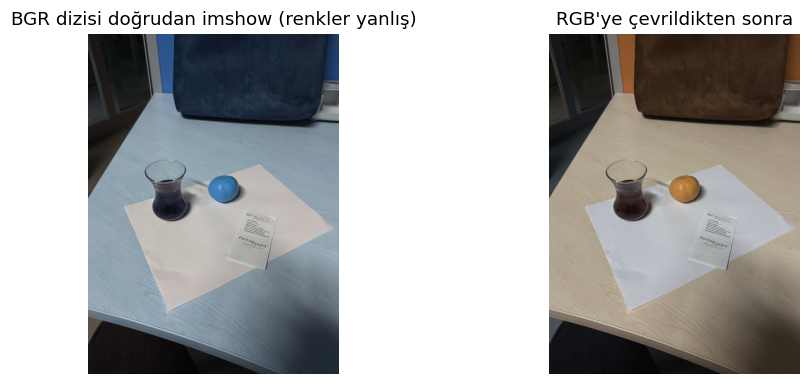

In [11]:
x, y = PIKSELLER[0]
print(f"P1 = (x={x}, y={y})")
print("BGR[y, x]          :", BGR["normal"][y, x], "  -> OpenCV sırası (B, G, R)")
print("BGR[y, x, 2]       :", BGR["normal"][y, x, 2], "  -> R kanalı BGR'de indeks 2'dedir")
print("RGB[y, x]          :", RGB["normal"][y, x], "  -> cv2.cvtColor(..., COLOR_BGR2RGB) sonrası")
print("BGR[y, x, ::-1]    :", BGR["normal"][y, x, ::-1], "  -> kanalları ters çevirmek aynı sonucu verir")
assert np.array_equal(RGB["normal"][y, x], BGR["normal"][y, x, ::-1])

# Sık yapılan hata: [x, y] sırası. Kare olmayan görüntüde başka bir pikseli okur ya da sınır dışına çıkar.
try:
    print("BGR[x, y] (YANLIŞ) :", BGR["normal"][x, y], "  -> farklı bir piksel")
except IndexError as e:
    print("BGR[x, y] (YANLIŞ) : IndexError —", e)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].imshow(kucult_goster(BGR["normal"])); ax[0].set_title("BGR dizisi doğrudan imshow (renkler yanlış)")
ax[1].imshow(kucult_goster(RGB["normal"])); ax[1].set_title("RGB'ye çevrildikten sonra")
for a in ax: a.axis("off")
fig.tight_layout(); fig.savefig(cikti("03_bgr_rgb.png"), dpi=150); plt.show()

### 4b — Aynı üç pikselin üç fotoğraftaki RGB değerleri
`R, G, B` tek pikselin değeridir. `R_ort, G_ort, B_ort` aynı pikselin çevresindeki `KOMSULUK × KOMSULUK` karenin ortalamasıdır; tek piksel gürültülü olabileceği için kontrol amaçlıdır.

In [12]:
satirlar = []
r = KOMSULUK // 2
for i, (x, y) in enumerate(PIKSELLER, 1):
    for k in FOTOLAR:
        R_, G_, B_ = RGB[k][y, x]
        blok = RGB[k][max(0, y - r):y + r + 1, max(0, x - r):x + r + 1].reshape(-1, 3).astype(float)
        satirlar.append({"piksel": f"P{i}", "x": x, "y": y, "foto": k,
                         "R": int(R_), "G": int(G_), "B": int(B_),
                         "R_ort": blok[:, 0].mean(), "G_ort": blok[:, 1].mean(), "B_ort": blok[:, 2].mean()})
PIKSEL_TABLO = pd.DataFrame(satirlar)
PIKSEL_TABLO.to_csv(cikti("adim4_pikseller.csv"), index=False, encoding="utf-8-sig")
display(PIKSEL_TABLO)

# normal ışığa göre oran: her kanal aynı oranda mı değişiyor?
oran = []
for p, g in PIKSEL_TABLO.groupby("piksel"):
    n = g[g.foto == "normal"][["R_ort", "G_ort", "B_ort"]].values[0]
    for _, s in g.iterrows():
        oran.append({"piksel": p, "foto": s.foto,
                     **{f"{c}/{c}_normal": s[f"{c}_ort"] / max(n[j], 1e-9) for j, c in enumerate("RGB")}})
display(pd.DataFrame(oran))

,piksel,x,y,foto,R,G,B,R_ort,G_ort,B_ort
0,P1,2180,2520,normal,193,149,100,204.40,160.08,110.84
1,P1,2180,2520,golge,156,116,75,159.40,120.00,78.40
2,P1,2180,2520,lamba,227,190,148,218.96,180.60,139.48
3,P2,2320,2580,normal,162,110,50,165.12,113.28,52.80
4,P2,2320,2580,golge,130,89,37,133.56,91.96,40.24
5,P2,2320,2580,lamba,175,121,56,178.56,124.36,59.88
6,P3,1750,3400,normal,190,195,201,186.44,191.44,197.44
7,P3,1750,3400,golge,164,165,169,163.84,164.84,168.84
8,P3,1750,3400,lamba,189,204,235,186.88,201.88,232.88


,piksel,foto,R/R_normal,G/G_normal,B/B_normal
0,P1,normal,1.000,1.000,1.000
1,P1,golge,0.780,0.750,0.707
2,P1,lamba,1.071,1.128,1.258
3,P2,normal,1.000,1.000,1.000
4,P2,golge,0.809,0.812,0.762
5,P2,lamba,1.081,1.098,1.134
6,P3,normal,1.000,1.000,1.000
7,P3,golge,0.879,0.861,0.855
8,P3,lamba,1.002,1.055,1.179


**Gözlem (Adım 4):**
- **Ne gördüm?** Mandalinadaki `P1(2180, 2520)`, `P2(2320, 2580)` ve beyaz A4 kâğıttaki `P3(1750, 3400)` pikselleri `golge` (`IMG_7104`) fotoğrafında üç kanalda da düştü (`P2` 5×5 ort.: `[165.1, 113.3, 52.8]` → `[133.6, 92.0, 40.2]`). `lamba` (`IMG_7107`) fotoğrafında mandalina pikselleri üç kanalda da yükseldi (`P2`: `[178.6, 124.4, 59.9]`). Kâğıtta (`P3`) ise lambada yalnız G ve B arttı (`B: 197.4 → 232.9`), R neredeyse aynı kaldı (`186.4 → 186.9`). Tek piksel ile 5×5 ortalaması arasındaki fark çoğu yerde 5 birimin altında, ama `P1` normal fotoğrafta 11 birime kadar çıkıyor (`193` ↔ `204.4`). Ayrıca gölge fotoğrafı bütün olarak daha karanlık değil: gri ortalaması normalde 113, gölgede 129; masa gölge fotoğrafında daha aydınlık, yalnızca mandalina ve kâğıdın olduğu bölge daha karanlık.
- **Neden olabilir?** EXIF'e göre üç çekimde de ISO 160 ve 0.01 s; kamera pozlamayı değiştirmemiş, yani farklar büyük ölçüde nesneye gelen ışıktan geliyor. Gölge yalnızca nesnelerin üstüne düşürüldüğü için masanın geri kalanı etkilenmemiş olabilir. Lambanın ışığı soğuk beyaz (mavi ağırlıklı) olduğu ve otomatik beyaz dengesi açık olduğu için kâğıtta B artarken R değişmemiş olabilir. `P1`'deki 11 birimlik fark, noktanın mandalinanın parlak ve pürüzlü yüzeyine denk gelmesinden kaynaklanabilir.
- **Nasıl kontrol ederim?** EXIF tablosunda ISO ve pozlama süresinin üç çekimde aynı olduğunu; `P3` için `B/B_normal` (`1.18`) oranının `R/R_normal` (`1.00`) oranından büyük olduğunu kontrol ederim. Gölgenin yalnız nesneye düştüğünü, masadan seçtiğim bir bölgenin üç fotoğraftaki ortalamasını karşılaştırarak kontrol ederim.
- **Tahminim tuttu mu?** Kısmen. Gölgede değerlerin düşmesi ve lambada mandalinanın üç kanalının artması tuttu. Kâğıdın lambada R kanalı artmadı; komşu pikseller `P1`'de beklediğim kadar yakın çıkmadı.

## Adım 5 — Sabit RGB ve HSV eşikleri (Hedef 2)

### 5a — Örnek bölgenin değerleri (eşikleri seçmek için)
Aşağıdaki yüzdelikler yalnızca **normal** fotoğraftaki örnek bölgeden hesaplanır. Eşikler bu değerlere bakılarak parametreler hücresinde belirlendi ve sonra değiştirilmedi.

TAHMİN (adim5_esik): Sabit RGB eşikleriyle yaptığım maskenin normal fotoğrafta mandalinayı iyi yakalayacağını, ancak gölgede mandalina kararınca piksellerin çoğunu kaçıracağını düşünüyorum. HSV maskesinin ise ışık değişse bile mandalinanın turuncu tonunu tanımaya devam edeceğini ama sıcak/sarımsı masa ve duvar yüzeylerinden de parçalar seçebileceğini tahmin ediyorum.


,R,G,B,H,S,V
%1,139.0,95.0,38.0,15.0,83.0,139.0
%5,151.0,102.0,44.0,15.0,131.0,151.0
medyan,176.0,122.0,61.0,16.0,166.0,176.0
%95,205.0,156.0,99.0,17.0,183.0,205.0
%99,245.0,210.0,163.0,18.0,190.0,245.0


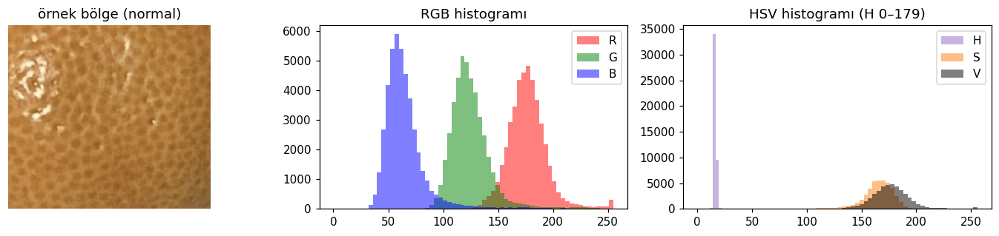

In [13]:
tahmini_goster("adim5_esik")
x, y, w, h = ORNEK_BOLGE
ornek_rgb = RGB["normal"][y:y + h, x:x + w].reshape(-1, 3)
ornek_hsv = cv2.cvtColor(BGR["normal"][y:y + h, x:x + w], cv2.COLOR_BGR2HSV).reshape(-1, 3)
yuzdelik = pd.DataFrame(
    {ad: np.percentile(v, [1, 5, 50, 95, 99]) for ad, v in
     zip(["R", "G", "B", "H", "S", "V"], list(ornek_rgb.T) + list(ornek_hsv.T))},
    index=["%1", "%5", "medyan", "%95", "%99"])
display(yuzdelik)

fig, ax = plt.subplots(1, 3, figsize=(13, 3))
ax[0].imshow(RGB["normal"][y:y + h, x:x + w]); ax[0].set_title("örnek bölge (normal)"); ax[0].axis("off")
for c, renk in zip(range(3), "rgb"):
    ax[1].hist(ornek_rgb[:, c], bins=64, range=(0, 255), color=renk, alpha=0.5, label="RGB"[c])
ax[1].set_title("RGB histogramı"); ax[1].legend()
for c, renk, ad, ust in zip(range(3), ["tab:purple", "tab:orange", "k"], "HSV", [180, 256, 256]):
    ax[2].hist(ornek_hsv[:, c], bins=64, range=(0, ust), color=renk, alpha=0.5, label=ad)
ax[2].set_title("HSV histogramı (H 0–179)"); ax[2].legend()
fig.tight_layout(); fig.savefig(cikti("04_ornek_bolge.png"), dpi=150); plt.show()

### 5b — Eşikleri dondur ve üç fotoğrafa aynen uygula

In [14]:
DONMUS_ESIK = json.loads(json.dumps({"RGB": RGB_ESIK, "HSV": HSV_ESIK}))   # kopya: sonradan değişmesin
with open(cikti("donmus_esikler.json"), "w", encoding="utf-8") as f:
    json.dump(DONMUS_ESIK, f, indent=2, ensure_ascii=False)
print("Dondurulmuş eşikler:", DONMUS_ESIK)

def rgb_maske(rgb, e):
    alt = np.array([e["R"][0], e["G"][0], e["B"][0]], np.uint8)
    ust = np.array([e["R"][1], e["G"][1], e["B"][1]], np.uint8)
    return cv2.inRange(rgb, alt, ust)                  # rgb dizisi RGB sırasında

def hsv_maske(bgr, e):
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)         # 8 bit: H 0–179
    (h1, h2), (s1, s2), (v1, v2) = e["H"], e["S"], e["V"]
    if h1 <= h2:
        return cv2.inRange(hsv, np.array([h1, s1, v1], np.uint8), np.array([h2, s2, v2], np.uint8))
    m1 = cv2.inRange(hsv, np.array([h1, s1, v1], np.uint8), np.array([179, s2, v2], np.uint8))
    m2 = cv2.inRange(hsv, np.array([0, s1, v1], np.uint8), np.array([h2, s2, v2], np.uint8))
    return cv2.bitwise_or(m1, m2)

MASKELER = {}
for k in FOTOLAR:
    MASKELER[(k, "RGB")] = rgb_maske(RGB[k], DONMUS_ESIK["RGB"])
    MASKELER[(k, "HSV")] = hsv_maske(BGR[k], DONMUS_ESIK["HSV"])
    for uzay in ("RGB", "HSV"):
        cv2.imwrite(cikti(f"maske_{uzay}_{k}.png"), MASKELER[(k, uzay)])

Dondurulmuş eşikler: {'RGB': {'R': [150, 215], 'G': [100, 155], 'B': [40, 90]}, 'HSV': {'H': [12, 22], 'S': [120, 205], 'V': [140, 220]}}


In [15]:
def ton_ortalamasi(h):
    # H dairesel bir büyüklüktür (179'dan sonra 0 gelir); aritmetik ortalama kırmızıda yanıltır
    aci = h.astype(np.float64) * np.pi / 90.0           # 0–179 -> 0–2π
    return (np.degrees(np.arctan2(np.sin(aci).mean(), np.cos(aci).mean())) / 2.0) % 180

x, y, w, h = ORNEK_BOLGE
satirlar = []
for (k, uzay), m in MASKELER.items():
    secilen = int(np.count_nonzero(m))
    ic = int(np.count_nonzero(m[y:y + h, x:x + w]))
    ornek = RGB[k][y:y + h, x:x + w].reshape(-1, 3).mean(0)
    hsv_px = cv2.cvtColor(BGR[k][y:y + h, x:x + w], cv2.COLOR_BGR2HSV).reshape(-1, 3)
    ornek_h = [ton_ortalamasi(hsv_px[:, 0]), hsv_px[:, 1].mean(), hsv_px[:, 2].mean()]
    satirlar.append({"foto": k, "uzay": uzay, "secilen_piksel": secilen, "toplam_piksel": H * W,
                     "alan_orani_%": 100 * secilen / (H * W),
                     "ornek_bolgede_secilen_%": 100 * ic / (w * h),
                     "ornek_bolge_disinda_secilen": secilen - ic,
                     "ornek_ort_R": ornek[0], "ornek_ort_G": ornek[1], "ornek_ort_B": ornek[2],
                     "ornek_ort_H": ornek_h[0], "ornek_ort_S": ornek_h[1], "ornek_ort_V": ornek_h[2]})
MASKE_TABLO = pd.DataFrame(satirlar)
MASKE_TABLO.to_csv(cikti("adim5_maskeler.csv"), index=False, encoding="utf-8-sig")
display(MASKE_TABLO)
print("Not: alan oranı bir doğruluk ölçütü değildir; yalnızca eşiği geçen piksel oranıdır.")
print("Not: ornek_ort_H dairesel ortalamadır (0/179 sınırını saran kırmızı tonlarda da doğru).")

,foto,uzay,secilen_piksel,toplam_piksel,alan_orani_%,ornek_bolgede_secilen_%,ornek_bolge_disinda_secilen,ornek_ort_R,ornek_ort_G,ornek_ort_B,ornek_ort_H,ornek_ort_S,ornek_ort_V
0,normal,RGB,120278,23006080,0.523,87.745,81670,176.955,125.136,65.079,16.146,162.688,176.955
1,normal,HSV,269685,23006080,1.172,95.293,227756,176.955,125.136,65.079,16.146,162.688,176.955
2,golge,RGB,16973,23006080,0.074,17.943,9078,142.798,99.713,49.465,16.179,167.858,142.798
3,golge,HSV,63327,23006080,0.275,56.750,38357,142.798,99.713,49.465,16.179,167.858,142.798
4,lamba,RGB,116997,23006080,0.509,79.718,81921,187.145,136.655,79.070,15.903,148.835,187.145
5,lamba,HSV,128938,23006080,0.560,88.150,90152,187.145,136.655,79.070,15.903,148.835,187.145


Not: alan oranı bir doğruluk ölçütü değildir; yalnızca eşiği geçen piksel oranıdır.
Not: ornek_ort_H dairesel ortalamadır (0/179 sınırını saran kırmızı tonlarda da doğru).


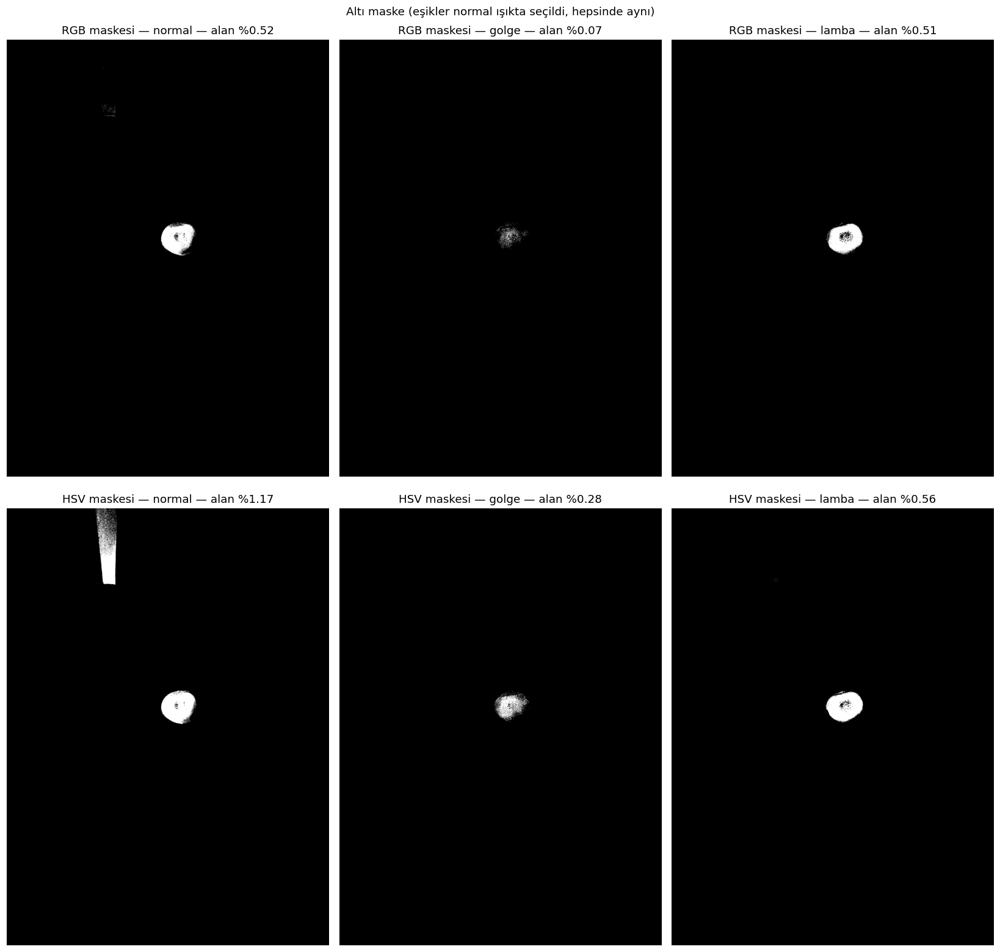

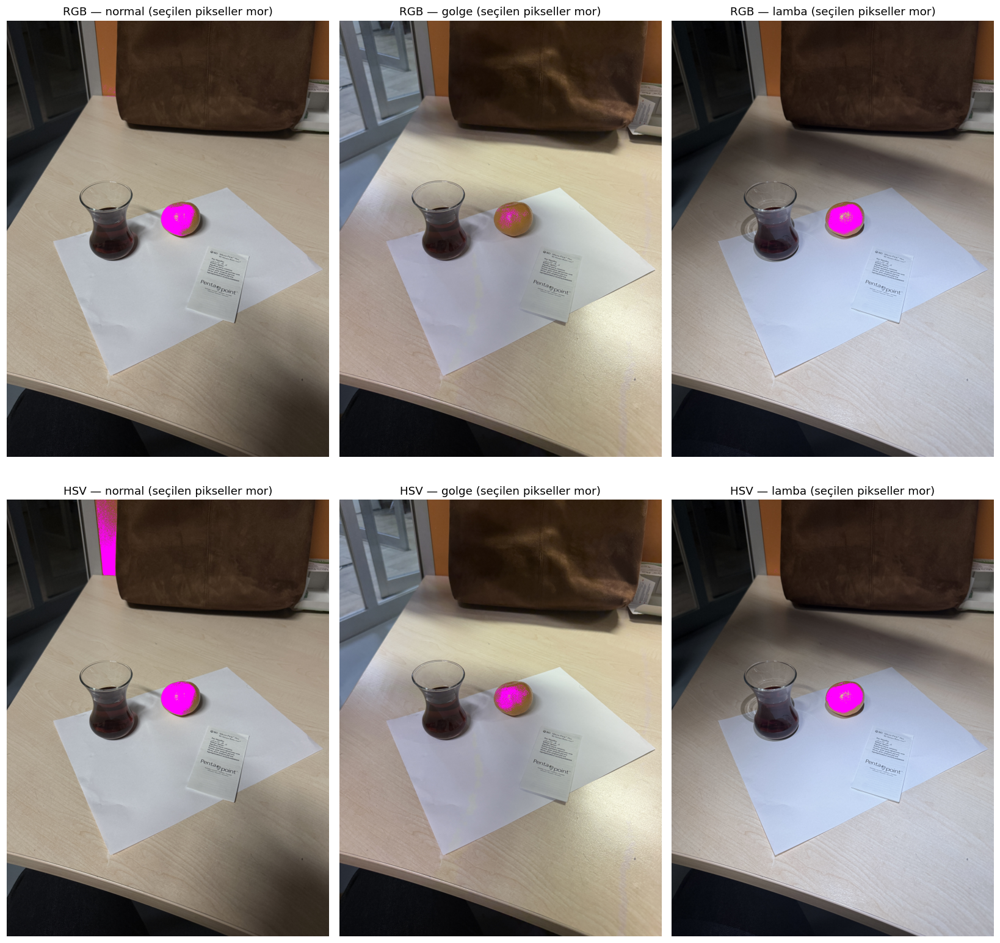

In [16]:
fig, ax = plt.subplots(2, 3, figsize=(15, 10 * H / W + 1.2))
for j, k in enumerate(FOTOLAR):
    for i, uzay in enumerate(("RGB", "HSV")):
        m = MASKELER[(k, uzay)]
        oran = 100 * np.count_nonzero(m) / m.size
        ax[i, j].imshow(kucult_goster(m), cmap="gray", extent=(0, W, H, 0), vmin=0, vmax=255)
        ax[i, j].set_title(f"{uzay} maskesi — {k} — alan %{oran:.2f}")
        ax[i, j].axis("off")
fig.suptitle("Altı maske (eşikler normal ışıkta seçildi, hepsinde aynı)")
fig.tight_layout(); fig.savefig(cikti("05_alti_maske.png"), dpi=150); plt.show()

# Maskeyi fotoğrafın üzerine bindir: seçilen yer nesne mi, arka plan mı?
fig, ax = plt.subplots(2, 3, figsize=(15, 10 * H / W + 1.2))
for j, k in enumerate(FOTOLAR):
    for i, uzay in enumerate(("RGB", "HSV")):
        g = RGB[k].copy()
        g[MASKELER[(k, uzay)] > 0] = (255, 0, 255)
        ax[i, j].imshow(kucult_goster(g), extent=(0, W, H, 0))
        ax[i, j].set_title(f"{uzay} — {k} (seçilen pikseller mor)")
        ax[i, j].axis("off")
fig.tight_layout(); fig.savefig(cikti("06_maske_bindirme.png"), dpi=150); plt.show()

**Gözlem (Adım 5):**
- **Ne gördüm?** Normal fotoğrafta dondurduğum RGB eşiği (`R:[150,215], G:[100,155], B:[40,90]`) örnek bölgenin normalde `%87.7`'sini, gölgede `%17.9`'unu, lambada `%79.7`'sini seçti. HSV eşiği (`H:[12,22], S:[120,205], V:[140,220]`) normalde `%95.3`, gölgede `%56.8`, lambada `%88.2` seçti; yani HSV de gölgede `38.5` puan düştü, sadece RGB'den (`69.8` puan) daha az. Maskeleri bağlı bileşenlere ayırınca: RGB maskelerinin hepsi neredeyse yalnızca mandalinayı seçiyor (RGB-normal'de mandalina dışında yalnızca `1.269` piksel). Tablodaki `ornek_bolge_disinda_secilen = 81.670` piksel büyük ölçüde mandalinanın örnek kutusu dışında kalan kısmı, arka plan değil. HSV-normal maskesinde ise mandalinadan ayrı, yaklaşık `115 bin` piksellik tek bir parça var: sol üstteki turuncu duvar şeridi (x ≈ 1160–1400, y ≈ 180–980). Bu şerit gölge ve lamba HSV maskelerinde seçilmedi.
- **Neden olabilir?** RGB'de üç sınır da parlaklığa bağlı; gölgede mandalinanın R ve G değerleri `150` ve `100`'ün altına inince pikseller maskeden çıkıyor. HSV'de ton (H) parlaklıktan kısmen ayrıdır, ama V alt sınırı (`140`) da sabit olduğu için kararan pikseller HSV maskesinden de düşüyor; HSV ışık değişimine tam dayanıklı değil. Alan oranı doğruluk değildir: HSV-normal'in alan oranı (`%1.17`) RGB-normal'in (`%0.52`) iki katından fazla, ama bu farkın büyük kısmı mandalina değil duvar.
- **Rapor sorusu ("Sarı bir arka plan neden hedef gibi seçildi?"):** Benim sahnemde hedef gibi seçilen arka plan, HSV-normal maskesindeki turuncu duvar. Duvarın normal fotoğraftaki ortalaması yaklaşık `H ≈ 12.7, S ≈ 171, V ≈ 146`; üç değer de HSV aralığının içinde ve tonu mandalinayla aynı. Eşik nesneyi tanımaz, yalnızca pikselin sayılarına bakar. Gölge ve lamba fotoğraflarında duvarın parlaklığı `V ≈ 120`'ye düştüğü için `V ≥ 140` sınırının altında kaldı ve seçilmedi; yani duvar sadece parlaklığı uygun olduğu fotoğrafta seçildi. Bej masa ise hiçbir maskede seçilmedi: normal fotoğrafta tonu (`H ≈ 18`) aralığın içinde ama doygunluğu (`S ≈ 46`) `120`'nin altında; RGB'de de B değeri (`100`'ün üstünde) `90`'ın üstünde.
- **Nasıl kontrol ederim?** Maskelerde bağlı bileşen analiziyle seçilen parçaların yerini ve büyüklüğünü bulurum; duvar ve masadan aldığım bölgelerin HSV ortalamalarını eşik aralıklarıyla karşılaştırırım. V alt sınırını biraz yükseltip duvarın maskeden çıktığını, mandalinanın ise büyük ölçüde kaldığını görebilirim.
- **Tahminim tuttu mu?** Kısmen. Sabit RGB eşiğinin gölgede mandalinanın çoğunu kaçıracağı tuttu. HSV'nin ışık değişse de mandalinayı tanımaya devam edeceği tutmadı (gölgede `%56.8`). Sıcak renkli yüzeylerin seçilebileceği duvarda (yalnız normal fotoğrafta) tuttu, masada tutmadı.

## Adım 6 — Parlaklık kaydırması ve gama (Hedef 3)
- Parlaklık: $J = \mathrm{clip}(I + b,\ 0,\ 255)$
- Gama: $J = 255 \cdot (I/255)^{\gamma}$ — bu ödevde γ formüldeki üstür.

İşlemler `float64` üzerinde yapılır, [0, 255] aralığına kırpılır. Ortalamalar kırpılmış float sonuç üzerinden ölçülür; görsel kaydetmek için ayrıca `uint8`'e yuvarlanır.

In [17]:
def parlaklik(I, b):
    return np.clip(I.astype(np.float64) + b, 0, 255)

def gama(I, g):
    return np.clip(255.0 * (I.astype(np.float64) / 255.0) ** g, 0, 255)

def u8(J):
    return np.round(J).astype(np.uint8)

# Formül kontrolü (ödevdeki örnek): 64 -> γ=0,5 ile ≈128, γ=2,0 ile ≈16
ornek = np.array([64], np.uint8)
print("64, γ=0.5 ->", gama(ornek, 0.5)[0].round(2), "| 64, γ=2.0 ->", gama(ornek, 2.0)[0].round(2))

I = RGB["normal"]
ORT_ONCE = I.astype(np.float64).mean()
print(f"Normal fotoğrafın ortalaması (tüm kanallar, tüm pikseller): {ORT_ONCE:.2f}")
print("Şimdi aşağıdaki hücreye her dönüşüm için sayısal ortalama tahminini yaz, sonra devam et.")

64, γ=0.5 -> 127.75 | 64, γ=2.0 -> 16.06
Normal fotoğrafın ortalaması (tüm kanallar, tüm pikseller): 110.86
Şimdi aşağıdaki hücreye her dönüşüm için sayısal ortalama tahminini yaz, sonra devam et.


In [18]:
# ===== SAYISAL TAHMİNLER (ölçmeden önce doldur) =====
ORTALAMA_TAHMINI = {"parlaklik_b+40": 150.86, "gama_0.5": 168.13, "gama_2.0": 48.19}

In [19]:
tahmini_goster("adim6_parlaklik")
tahmini_goster("adim6_gama")

SONUC6 = {}
satirlar = []

J = parlaklik(I, PARLAKLIK_B)
ad = f"parlaklik_b{PARLAKLIK_B:+d}"
SONUC6[ad] = J
tasan = I.astype(np.float64) + PARLAKLIK_B > 255
satirlar.append({"dönüşüm": ad,
                 "tahmin": ORTALAMA_TAHMINI.get(ad),
                 "formül ortalamaya uygulanırsa": ORT_ONCE + PARLAKLIK_B,
                 "ölçülen ortalama": J.mean(),
                 "255'te kırpılan kanal değeri %": 100 * tasan.mean(),
                 "0'da kırpılan kanal değeri %": 100 * (I.astype(np.float64) + PARLAKLIK_B < 0).mean(),
                 "kırpmanın ortalamadan götürdüğü": (I.astype(np.float64) + PARLAKLIK_B - 255).clip(0).mean()})

for g in GAMALAR:
    ad = f"gama_{g}"
    J = gama(I, g)
    SONUC6[ad] = J
    satirlar.append({"dönüşüm": ad,
                     "tahmin": ORTALAMA_TAHMINI.get(ad),
                     "formül ortalamaya uygulanırsa": 255 * (ORT_ONCE / 255) ** g,
                     "ölçülen ortalama": J.mean(),
                     # 0–255 girdide gama çıktısı da 0–255 içinde kalır; kırpma oluşmaz
                     "255'te kırpılan kanal değeri %": np.nan,
                     "0'da kırpılan kanal değeri %": np.nan,
                     "kırpmanın ortalamadan götürdüğü": np.nan})

DONUSUM_TABLO = pd.DataFrame(satirlar)
DONUSUM_TABLO.insert(1, "önceki ortalama", ORT_ONCE)
DONUSUM_TABLO["ölçülen − tahmin"] = [
    (r["ölçülen ortalama"] - r["tahmin"]) if pd.notna(r["tahmin"]) else np.nan for _, r in DONUSUM_TABLO.iterrows()]
DONUSUM_TABLO.to_csv(cikti("adim6_donusumler.csv"), index=False, encoding="utf-8-sig")
display(DONUSUM_TABLO)
if any(v is None for v in ORTALAMA_TAHMINI.values()):
    print("UYARI: ORTALAMA_TAHMINI içinde boş tahmin var.")

# Kanal bazında ortalamalar
display(pd.DataFrame({"orijinal": I.reshape(-1, 3).mean(0),
                      **{k: v.reshape(-1, 3).mean(0) for k, v in SONUC6.items()}}, index=["R", "G", "B"]).T)

for k, v in SONUC6.items():
    # yalnız rapora koymak için 1600 px genişlikte kaydedilir (ölçümler tam çözünürlükte yapıldı)
    cv2.imwrite(cikti(f"adim6_{k}.jpg"), kucult_goster(cv2.cvtColor(u8(v), cv2.COLOR_RGB2BGR), 1600), [cv2.IMWRITE_JPEG_QUALITY, 92])

TAHMİN (adim6_parlaklik): Görüntüye +40 parlaklık eklediğimde tüm fotoğrafın açılacağını ve ortalamanın yaklaşık 40 puan yükseleceğini tahmin ediyorum. Beyaz kağıt gibi çok açık renkli bölgelerin 255'i geçerek kırpılacağını ve ortalamayı 150.86'nın biraz altına düşüreceğini öngörüyorum.
TAHMİN (adim6_gama): γ = 0.5 uygulandığında gölgede kalan masa ve çay bardağı kısımlarının açılıp genel ortalamanın yaklaşık 168 civarına yükseleceğini tahmin ediyorum. γ = 2.0 uygulandığında ise koyu ve orta tonların iyice siyaha yaklaşarak ortalamayı 48 civarına düşüreceğini öngörüyorum.


,dönüşüm,önceki ortalama,tahmin,formül ortalamaya uygulanırsa,ölçülen ortalama,255'te kırpılan kanal değeri %,0'da kırpılan kanal değeri %,kırpmanın ortalamadan götürdüğü,ölçülen − tahmin
0,parlaklik_b+40,110.855,150.86,150.855,150.846,0.039,0.0,0.009,-0.014
1,gama_0.5,110.855,168.13,168.131,158.494,NaN,NaN,NaN,-9.636
2,gama_2.0,110.855,48.19,48.192,64.165,NaN,NaN,NaN,15.975


,R,G,B
orijinal,119.743,111.191,101.632
parlaklik_b+40,159.731,151.182,141.626
gama_0.5,166.109,158.855,150.519
gama_2.0,71.768,64.368,56.358


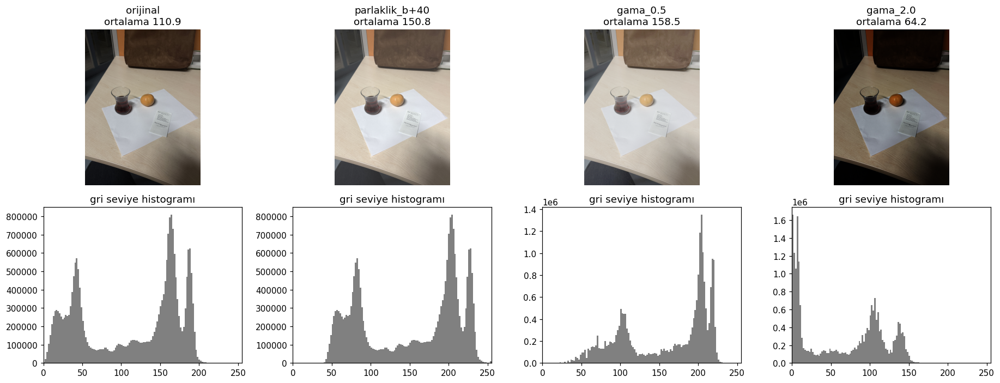

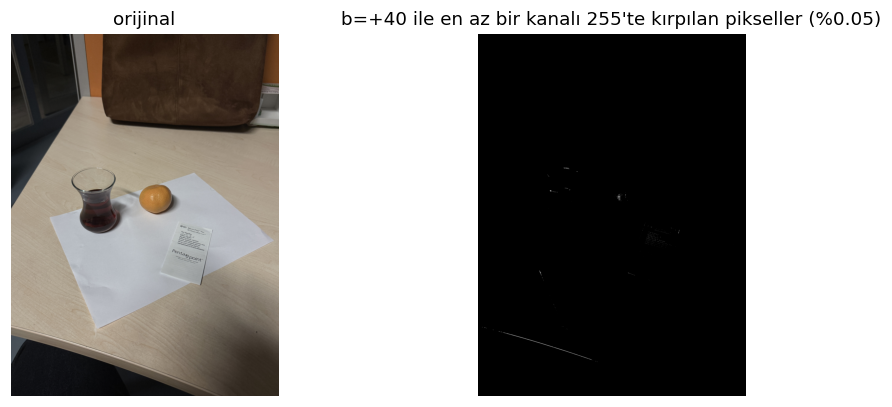

In [20]:
gorseller = {"orijinal": I.astype(np.float64), **SONUC6}
fig, ax = plt.subplots(2, len(gorseller), figsize=(4.2 * len(gorseller), 6.5))
for j, (k, v) in enumerate(gorseller.items()):
    ax[0, j].imshow(kucult_goster(u8(v))); ax[0, j].set_title(f"{k}\nortalama {v.mean():.1f}"); ax[0, j].axis("off")
    gri = cv2.cvtColor(u8(v), cv2.COLOR_RGB2GRAY)
    ax[1, j].hist(gri.ravel(), bins=128, range=(0, 255), color="gray")
    ax[1, j].set_xlim(0, 255); ax[1, j].set_title("gri seviye histogramı")
fig.tight_layout(); fig.savefig(cikti("07_parlaklik_gama.png"), dpi=150); plt.show()

# 255'te kırpılan pikselleri göster (b = +40)
tasma_maskesi = (I.astype(np.float64) + PARLAKLIK_B > 255).any(axis=2)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].imshow(kucult_goster(I)); ax[0].set_title("orijinal"); ax[0].axis("off")
ax[1].imshow(kucult_goster(tasma_maskesi.astype(np.uint8) * 255), cmap="gray")
ax[1].set_title(f"b={PARLAKLIK_B:+d} ile en az bir kanalı 255'te kırpılan pikseller (%{100 * tasma_maskesi.mean():.2f})")
ax[1].axis("off")
fig.tight_layout(); fig.savefig(cikti("08_kirpilan_pikseller.png"), dpi=150); plt.show()

**Kontrol: uint8 taşması.** Dönüşümü `float` yerine doğrudan `uint8` üzerinde yapmak sessizce yanlış sonuç verir.

In [21]:
d = np.array([100, 200, 220, 250], np.uint8)
print("değerler                 :", d)
print("uint8 + 40 (taşar, YANLIŞ):", d + np.uint8(40))
print("cv2.add (doyurur)        :", cv2.add(d.reshape(1, -1), np.full((1, d.size), 40, np.uint8)).ravel())
print("float + clip (bu ödev)   :", u8(parlaklik(d, 40)))

değerler                 : [100 200 220 250]
uint8 + 40 (taşar, YANLIŞ): [140 240   4  34]
cv2.add (doyurur)        : [140 240 255 255]
float + clip (bu ödev)   : [140 240 255 255]


**Gözlem (Adım 6):**
- **Ne gördüm?** Normal fotoğrafın ortalaması `110.86`.
  1. `+40` parlaklıkta ölçülen ortalama `150.85`, formül beklentisi `150.86`. Kanal değerlerinin `%0.04`'ü (en az bir kanalı kırpılan piksellerin `%0.05`'i) 255'te kırpıldı. `08_kirpilan_pikseller.png`'de kırpılan piksellerin çoğu (yaklaşık `%58`) masanın ön kenarındaki parlak şeritte; kalanı prospektüs kartında (~`%17`), mandalinanın parlak noktasında (~`%11`) ve bardağın kenarında.
  2. $\gamma = 0.5$'te ölçülen ortalama `158.49`, formülü ortalamaya uygulayınca `168.13`.
  3. $\gamma = 2.0$'da ölçülen ortalama `64.16`, formülle `48.19`.
- **Neden olabilir?** Kâğıdın değerleri normal fotoğrafta yaklaşık `180–200`; `+40` ile `240`'ı geçmediği için kâğıt kırpılmadı, yalnızca zaten çok parlak olan küçük alanlar kırpıldı. Gama doğrusal olmadığı için "ortalamanın gaması" ile "gamaların ortalaması" aynı değildir (Jensen eşitsizliği): $\gamma = 0.5$ içbükey olduğu için ölçülen ortalama formülden düşük, $\gamma = 2.0$ dışbükey olduğu için yüksek çıkar.
- **Nasıl kontrol ederim?** Kırpmanın götürdüğü `0.009` birimi ölçülen ortalamaya ekleyince `150.855 = 110.855 + 40` çıkıyor. Kırpılan piksellerin yerini `08_kirpilan_pikseller.png`'de, histogramın 40 birim sağa kaydığını `07_parlaklik_gama.png`'de kontrol ederim.
- **Tahminim tuttu mu?** Kısmen. Ortalamanın `150.86`'nın biraz altında kalacağı tuttu (`0.009` birim). Beyaz kâğıdın 255'i geçip kırpılacağı tutmadı. Gamada yön doğru çıktı (0.5 açtı, 2.0 kararttı), ama sayısal tahminler tutmadı: $\gamma = 0.5$'te `−9.64`, $\gamma = 2.0$'da `+15.97` fark var.

## Adım 7 — Küçültmenin etkisi (Hedef 4)
Yazı bölgesi genişlik ve yükseklikte 1/`KUCULTME` oranında küçültülür (`INTER_NEAREST` ve `INTER_AREA`), sonra **yalnızca göstermek için** `INTER_NEAREST` ile özgün boyuta büyütülür.
Bölge, kenarları `KUCULTME`'nin katı olacak şekilde birkaç piksel kırpılabilir.

TAHMİN (adim7_kucultme): A4 kağıdı üzerindeki 'PentaPoint' yazılı prospektüs kartını 1/4 oranında küçültüp geri büyüttüğümde üstteki küçük açıklama yazılarının okunmaz hale geleceğini, büyük başlığın ise okunacağını düşünüyorum. INTER_NEAREST yönteminde harflerin tırtıklı ve kopuk görüneceğini, INTER_AREA yönteminde ise bulanıklaşsa bile harf şekillerinin daha bütün kalacağını tahmin ediyorum.
kesit: 640×760  ->  küçük: 160×190  ->  geri büyütülmüş: 640×760


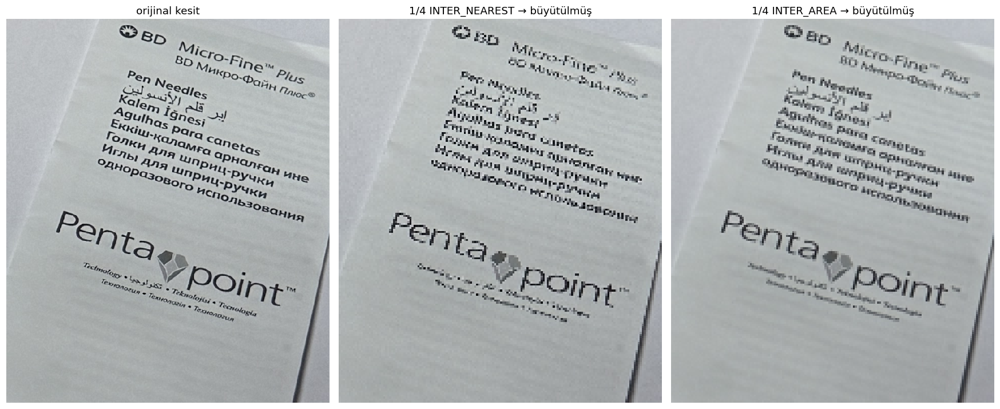

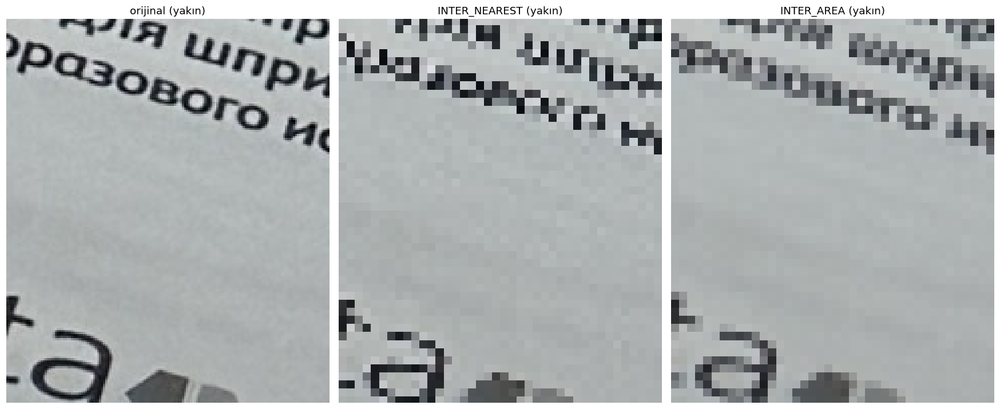

In [22]:
tahmini_goster("adim7_kucultme")
K = KUCULTME
x, y, w, h = YAZI_BOLGESI
w, h = (w // K) * K, (h // K) * K
KESIT = RGB["normal"][y:y + h, x:x + w]
kucuk = {
    "INTER_NEAREST": cv2.resize(KESIT, (w // K, h // K), interpolation=cv2.INTER_NEAREST),
    "INTER_AREA":    cv2.resize(KESIT, (w // K, h // K), interpolation=cv2.INTER_AREA),
}
buyuk = {k: cv2.resize(v, (w, h), interpolation=cv2.INTER_NEAREST) for k, v in kucuk.items()}
print(f"kesit: {KESIT.shape[1]}×{KESIT.shape[0]}  ->  küçük: {w // K}×{h // K}  ->  geri büyütülmüş: {w}×{h}")

cv2.imwrite(cikti("adim7_kesit_orijinal.png"), cv2.cvtColor(KESIT, cv2.COLOR_RGB2BGR))
for k in kucuk:
    cv2.imwrite(cikti(f"adim7_kucuk_{k}.png"), cv2.cvtColor(kucuk[k], cv2.COLOR_RGB2BGR))
    cv2.imwrite(cikti(f"adim7_buyutulmus_{k}.png"), cv2.cvtColor(buyuk[k], cv2.COLOR_RGB2BGR))

fig, ax = plt.subplots(1, 3, figsize=(16, 16 * h / (3 * w) + 1))
for a, (baslik, g) in zip(ax, [("orijinal kesit", KESIT),
                               (f"1/{K} INTER_NEAREST → büyütülmüş", buyuk["INTER_NEAREST"]),
                               (f"1/{K} INTER_AREA → büyütülmüş", buyuk["INTER_AREA"])]):
    a.imshow(g, interpolation="nearest"); a.set_title(baslik); a.axis("off")
fig.tight_layout(); fig.savefig(cikti("09_kucultme_yan_yana.png"), dpi=200); plt.show()

# Yakın plan: kesitin ortasındaki küçük bir parça
zx, zy, zw, zh = w // 2 - w // 8, h // 2 - h // 8, w // 4, h // 4
fig, ax = plt.subplots(1, 3, figsize=(16, 16 * zh / (3 * zw) + 1))
for a, (baslik, g) in zip(ax, [("orijinal (yakın)", KESIT), ("INTER_NEAREST (yakın)", buyuk["INTER_NEAREST"]),
                               ("INTER_AREA (yakın)", buyuk["INTER_AREA"])]):
    a.imshow(g[zy:zy + zh, zx:zx + zw], interpolation="nearest"); a.set_title(baslik); a.axis("off")
fig.tight_layout(); fig.savefig(cikti("10_kucultme_yakin.png"), dpi=200); plt.show()

In [23]:
def kenar_enerjisi(rgb):
    # ortalama mutlak Laplace: ince ayrıntı / keskin kenar miktarının kaba bir göstergesi
    gri = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(np.float64)
    return np.abs(cv2.Laplacian(gri, cv2.CV_64F)).mean()

satirlar = [{"yöntem": "orijinal", "boyut": f"{w}×{h}", "orijinale ort. mutlak fark": 0.0,
             "kenar enerjisi": kenar_enerjisi(KESIT), "gri std": cv2.cvtColor(KESIT, cv2.COLOR_RGB2GRAY).std(),
             "küçük→büyük→küçük aynı mı": "—"}]
for k in kucuk:
    tekrar = cv2.resize(buyuk[k], (w // K, h // K), interpolation=cv2.INTER_AREA)
    satirlar.append({"yöntem": k, "boyut": f"{w // K}×{h // K} → {w}×{h}",
                     "orijinale ort. mutlak fark": np.abs(buyuk[k].astype(float) - KESIT.astype(float)).mean(),
                     "kenar enerjisi": kenar_enerjisi(buyuk[k]),
                     "gri std": cv2.cvtColor(buyuk[k], cv2.COLOR_RGB2GRAY).std(),
                     "küçük→büyük→küçük aynı mı": bool(np.array_equal(tekrar, kucuk[k]))})
KUCULTME_TABLO = pd.DataFrame(satirlar)
KUCULTME_TABLO.to_csv(cikti("adim7_kucultme.csv"), index=False, encoding="utf-8-sig")
display(KUCULTME_TABLO)
print("Son sütun: geri büyütülmüş görüntü tekrar küçültüldüğünde küçük görüntünün aynısı mı çıkıyor?")

,yöntem,boyut,orijinale ort. mutlak fark,kenar enerjisi,gri std,küçük→büyük→küçük aynı mı
0,orijinal,640×760,0.000,9.258,31.534,—
1,INTER_NEAREST,160×190 → 640×760,9.310,12.068,31.438,True
2,INTER_AREA,160×190 → 640×760,6.361,8.382,26.180,True


Son sütun: geri büyütülmüş görüntü tekrar küçültüldüğünde küçük görüntünün aynısı mı çıkıyor?


**Gözlem (Adım 7):**
- **Ne gördüm?** Prospektüs kartındaki `640×760` kesiti `1/4` oranında (`160×190`) küçültüp ekranda görmek için geri büyüttüm. Kesitte büyük harf yükseklikleri yaklaşık şöyle: üstteki satırlar ("Pen Needles", "Kalem İğnesi", Kiril satırlar) `15–17 px`, `"PentaPoint"` `28–30 px`, logonun altındaki italik "Technology • Teknolojisi…" satırları `~8 px`. Küçültmede bunlar sırasıyla `~4 px`, `~7 px` ve `~2 px`'e indi. İtalik satırlar iki yöntemde de okunmuyor. Üstteki satırlar `INTER_NEAREST`'te kopuk ve basamaklı, Kiril satırların çoğu okunmuyor; `INTER_AREA`'da bulanık ama Latin satırlar okunuyor. `"PentaPoint"` iki yöntemde de okunuyor. Orijinale ortalama mutlak fark: NEAREST `9.31`, AREA `6.36`; kenar enerjisi: orijinal `9.26`, NEAREST `12.07`, AREA `8.38`.
- **Neden olabilir?** `INTER_NEAREST` her $4 \times 4$ bloktan tek pikseli alıp kalan 15'ini atar; ince çizgiler denk gelirse kalır, gelmezse kaybolur ve sahte keskin kenarlar oluşur (kenar enerjisi orijinalden yüksek). `INTER_AREA` 16 pikselin ortalamasını alır: harfleri griye karıştırıp bulanıklaştırır ama sahte desen üretmez.
- **Rapor sorusu ("Büyütme kaybolan yazıyı neden geri getirmedi?"):** Küçültmede her eksende örnekleme 1/4'e, piksel sayısı 1/16'ya indi. ~2 px'e inen italik satırların harf çizgileri ve aralarındaki boşluklar bu aralıkta temsil edilemedi ve kalıcı olarak kayboldu. Büyütme yeni bilgi üretmez; `INTER_NEAREST` ile büyütmek kalan her pikseli yalnızca $4 \times 4$ blok olarak tekrarlar.
- **Nasıl kontrol ederim?** Büyütülmüş görüntüyü yeniden 1/4 küçültünce küçük görüntünün birebir aynısı çıkıyor (`adim7_kucultme.csv`: `küçük→büyük→küçük aynı mı = True`); yani büyütme bilgi eklemiyor. Harf yükseklikleri orijinal kesit üzerinde 10 px'lik ızgarayla ölçüldü.
- **Tahminim tuttu mu?** Kısmen. Büyük başlığın okunacağı, `INTER_NEAREST`'te harflerin tırtıklı ve kopuk, `INTER_AREA`'da daha bütün görüneceği tuttu. Üstteki küçük açıklama yazılarının okunmaz olacağı yalnızca `INTER_NEAREST`'te ve Kiril satırlarda kısmen tuttu; tamamen okunmaz olan, logonun altındaki daha küçük italik satırlar oldu.

## Sonuç tablosu ve parametre kaydı

In [24]:
uzun = []
for _, r in MASKE_TABLO.iterrows():
    uzun.append({"deney": "Adım 5 eşik", "koşul": f"{r['foto']} / {r['uzay']}", "ölçüt": "alan oranı %", "değer": r["alan_orani_%"]})
    uzun.append({"deney": "Adım 5 eşik", "koşul": f"{r['foto']} / {r['uzay']}", "ölçüt": "örnek bölgede seçilen %", "değer": r["ornek_bolgede_secilen_%"]})
for _, r in DONUSUM_TABLO.iterrows():
    for olcut in ["tahmin", "ölçülen ortalama", "255'te kırpılan kanal değeri %"]:
        uzun.append({"deney": "Adım 6 dönüşüm", "koşul": r["dönüşüm"], "ölçüt": olcut, "değer": r[olcut]})
for _, r in KUCULTME_TABLO.iterrows():
    for olcut in ["orijinale ort. mutlak fark", "kenar enerjisi"]:
        uzun.append({"deney": "Adım 7 küçültme", "koşul": r["yöntem"], "ölçüt": olcut, "değer": r[olcut]})
SONUC = pd.DataFrame(uzun)
SONUC.to_csv(cikti("sonuc_tablosu.csv"), index=False, encoding="utf-8-sig")
display(SONUC)

kayit = {
    "calistirma_zamani": datetime.datetime.now().isoformat(timespec="seconds"),
    "surumler": SURUMLER,
    "giris_dosyalari": {k: os.path.join(GIRIS_KLASORU, f) for k, f in FOTOLAR.items()},
    "sahne": SAHNE, "aciklama": ACIKLAMA,
    "goruntu_boyutu_HWC": [H, W, C],
    "hizalama": HIZALAMA_BILGI,
    "kamera_notu": KAMERA_NOTU,
    "exif": EXIF.to_dict(orient="index") if len(EXIF.columns) else {},
    "parametreler": {"PIKSELLER": PIKSELLER, "KOMSULUK": KOMSULUK, "ORNEK_BOLGE": ORNEK_BOLGE,
                     "RGB_ESIK": RGB_ESIK, "HSV_ESIK": HSV_ESIK, "PARLAKLIK_B": PARLAKLIK_B,
                     "GAMALAR": GAMALAR, "YAZI_BOLGESI": YAZI_BOLGESI, "KUCULTME": KUCULTME},
    "tahminler": TAHMINLER,
    "ortalama_tahmini": ORTALAMA_TAHMINI,
}
with open(cikti("parametreler.json"), "w", encoding="utf-8") as f:
    json.dump(kayit, f, indent=2, ensure_ascii=False, default=str)
print("Çıktılar:", sorted(os.listdir(CIKTI_KLASORU)))

,deney,koşul,ölçüt,değer
0,Adım 5 eşik,normal / RGB,alan oranı %,0.523
1,Adım 5 eşik,normal / RGB,örnek bölgede seçilen %,87.745
2,Adım 5 eşik,normal / HSV,alan oranı %,1.172
3,Adım 5 eşik,normal / HSV,örnek bölgede seçilen %,95.293
4,Adım 5 eşik,golge / RGB,alan oranı %,0.074
5,Adım 5 eşik,golge / RGB,örnek bölgede seçilen %,17.943
6,Adım 5 eşik,golge / HSV,alan oranı %,0.275
7,Adım 5 eşik,golge / HSV,örnek bölgede seçilen %,56.750
8,Adım 5 eşik,lamba / RGB,alan oranı %,0.509
9,Adım 5 eşik,lamba / RGB,örnek bölgede seçilen %,79.718


Çıktılar: ['00_hizalama.png', '01_fotograflar.png', '02_koordinatlar.png', '03_bgr_rgb.png', '04_ornek_bolge.png', '05_alti_maske.png', '06_maske_bindirme.png', '07_parlaklik_gama.png', '08_kirpilan_pikseller.png', '09_kucultme_yan_yana.png', '10_kucultme_yakin.png', 'adim4_pikseller.csv', 'adim5_maskeler.csv', 'adim6_donusumler.csv', 'adim6_gama_0.5.jpg', 'adim6_gama_2.0.jpg', 'adim6_parlaklik_b+40.jpg', 'adim7_buyutulmus_INTER_AREA.png', 'adim7_buyutulmus_INTER_NEAREST.png', 'adim7_kesit_orijinal.png', 'adim7_kucuk_INTER_AREA.png', 'adim7_kucuk_INTER_NEAREST.png', 'adim7_kucultme.csv', 'donmus_esikler.json', 'hizalama.csv', 'maske_HSV_golge.png', 'maske_HSV_lamba.png', 'maske_HSV_normal.png', 'maske_RGB_golge.png', 'maske_RGB_lamba.png', 'maske_RGB_normal.png', 'parametreler.json', 'sonuc_tablosu.csv']


## Teslim ZIP'i
Bu hücre notebook'u, raporu (`rapor.pdf`), kaynak beyanını, README'yi, fotoğrafları ve çıktıları `YZM411_Odev1_<OGRENCI_NO>.zip` dosyasında toplar. Eksik dosya varsa ZIP oluşturulmaz.

In [25]:
NOTEBOOK_DOSYASI = "YZM411_Odev1.ipynb"
EK_DOSYALAR = ["rapor.pdf", "kaynak_beyani.md", "README.md"]

assert OGRENCI_NO and OGRENCI_NO != "OgrenciNo", "Parametreler hücresinde OGRENCI_NO'yu yaz."
eksik = [f for f in [NOTEBOOK_DOSYASI] + EK_DOSYALAR if not os.path.exists(f)]
if eksik:
    raise FileNotFoundError(f"Teslim eksik, ZIP oluşturulmadı. Bulunamayan dosyalar: {eksik}")
zip_adi = f"YZM411_Odev1_{OGRENCI_NO}.zip"
with zipfile.ZipFile(zip_adi, "w", zipfile.ZIP_DEFLATED) as z:
    for f in [NOTEBOOK_DOSYASI] + EK_DOSYALAR:
        if os.path.exists(f):
            z.write(f)
    for klasor in ("fotograflar", "ciktilar"):           # girdi fotoğrafları ve çıktılar
        for kok, _, dosyalar in sorted(os.walk(klasor)):
            for ad in sorted(dosyalar):
                if not ad.startswith("."):
                    z.write(os.path.join(kok, ad))
with zipfile.ZipFile(zip_adi) as z:
    print(zip_adi, "—", len(z.namelist()), "dosya,", f"{os.path.getsize(zip_adi) / 1e6:.1f} MB")
    for n in z.namelist():
        print("  ", n)

YZM411_Odev1_230212903.zip — 40 dosya, 37.7 MB
   YZM411_Odev1.ipynb
   rapor.pdf
   kaynak_beyani.md
   README.md
   fotograflar/IMG_7104.JPG
   fotograflar/IMG_7106.JPG
   fotograflar/IMG_7107.JPG
   ciktilar/00_hizalama.png
   ciktilar/01_fotograflar.png
   ciktilar/02_koordinatlar.png
   ciktilar/03_bgr_rgb.png
   ciktilar/04_ornek_bolge.png
   ciktilar/05_alti_maske.png
   ciktilar/06_maske_bindirme.png
   ciktilar/07_parlaklik_gama.png
   ciktilar/08_kirpilan_pikseller.png
   ciktilar/09_kucultme_yan_yana.png
   ciktilar/10_kucultme_yakin.png
   ciktilar/adim4_pikseller.csv
   ciktilar/adim5_maskeler.csv
   ciktilar/adim6_donusumler.csv
   ciktilar/adim6_gama_0.5.jpg
   ciktilar/adim6_gama_2.0.jpg
   ciktilar/adim6_parlaklik_b+40.jpg
   ciktilar/adim7_buyutulmus_INTER_AREA.png
   ciktilar/adim7_buyutulmus_INTER_NEAREST.png
   ciktilar/adim7_kesit_orijinal.png
   ciktilar/adim7_kucuk_INTER_AREA.png
   ciktilar/adim7_kucuk_INTER_NEAREST.png
   ciktilar/adim7_kucultme.csv
   ciktila